# 05 — Manchester City: the Abu Dhabi Takeover

Sheikh Mansour bin Zayed Al Nahyan's Abu Dhabi United Group agreed to buy Manchester City on **1 September 2008** — deadline day of the 2008-09 season, which had already kicked off on 16 August. The deal completed on 23 September 2008. 1 September is the date the club and its fans mark as the takeover.

Sources: [2008-09 Manchester City F.C. season (Wikipedia)](https://en.wikipedia.org/wiki/2008%E2%80%9309_Manchester_City_F.C._season), [mancity.com: 12 years since the takeover](https://www.mancity.com/news/club/takeover-anniversary-gallery-63734552), [Premier League Archive: the Abu Dhabi Group takeover, September 2008](https://premierleague25years.wordpress.com/2018/12/12/iconic-moments-the-abu-dhabi-group-takeover-manchester-city-september-2008/).

This notebook:
1. Lists Manchester City's final table position in every season in the data, with the takeover marked.
2. Builds a function that recomputes a season's table **as if Manchester City had never played** — every other team keeps only its matches against the remaining 18/19/21 clubs.
3. Uses that function to ask: in the seasons City won the title, who would have won it without them?

This notebook is **read-only** and only reads `clean_data/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

ROOT = Path.cwd() if (Path.cwd() / "clean_data").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "scripts"))
from data_utils import load_matches, to_team_matches, league_table

TAKEOVER_SEASON = "2008-09"
TAKEOVER_SEASON_START_YEAR = 2008

BLUE, RED, GRAY = "#2a78d6", "#e34948", "#9a988f"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                      "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                      "figure.facecolor": "white", "axes.facecolor": "white"})

matches = load_matches()
team_matches = to_team_matches(matches)
matches["season"].nunique(), matches["season"].min(), matches["season"].max()

(34, '1992-93', '2025-26')

## 1. Manchester City's table position, every season available

"Every season available" means every season in the data where City played in the Premier League — they spent five seasons outside it (relegated in 1996 and 2001, promoted back in 2000 and 2002), so those years have no top-flight position to report.

In [2]:
def team_positions(team_matches: pd.DataFrame, team: str) -> pd.DataFrame:
    """A team's final position, points and table size for every season it appears in."""
    seasons = sorted(team_matches.loc[team_matches["team"] == team, "season"].unique())
    rows = []
    for season in seasons:
        table = league_table(team_matches, season)
        row = table[table["team"] == team].iloc[0]
        rows.append({"season": season, "season_start_year": int(season[:4]),
                      "position": int(table.index[table["team"] == team][0]),
                      "points": int(row["points"]), "teams_in_league": len(table)})
    return pd.DataFrame(rows)


city_positions = team_positions(team_matches, "Manchester City")
print(f"{len(city_positions)} seasons in the data")
city_positions

29 seasons in the data


,season,season_start_year,position,points,teams_in_league
0,1992-93,1992,9,57,22
1,1993-94,1993,16,45,22
2,1994-95,1994,17,49,22
3,1995-96,1995,18,38,20
4,2000-01,2000,18,34,20
5,2002-03,2002,9,51,20
6,2003-04,2003,16,41,20
7,2004-05,2004,8,52,20
8,2005-06,2005,15,43,20
9,2006-07,2006,14,42,20


In [3]:
all_seasons = sorted(matches["season_start_year"].unique())
missing = sorted(set(all_seasons) - set(city_positions["season_start_year"]))
missing_labels = [f"{y}-{str(y + 1)[-2:]}" for y in missing]
print(f"Seasons Manchester City are absent from the data (outside the Premier League): {missing_labels}")

Seasons Manchester City are absent from the data (outside the Premier League): ['1996-97', '1997-98', '1998-99', '1999-00', '2001-02']


In [4]:
# Test: sanity-checks against widely reported facts about this period
row_1112 = city_positions.set_index("season").loc["2011-12"]
assert row_1112["position"] == 1 and row_1112["points"] == 89, "2011-12: City's first title, won on goal difference"

pre = city_positions[city_positions["season_start_year"] < TAKEOVER_SEASON_START_YEAR]
post = city_positions[city_positions["season_start_year"] >= TAKEOVER_SEASON_START_YEAR]
print(f"average position before the takeover: {pre['position'].mean():.1f}  ({len(pre)} seasons)")
print(f"average position from {TAKEOVER_SEASON} on:   {post['position'].mean():.1f}  ({len(post)} seasons)")
print(f"titles before: {(pre['position'] == 1).sum()}  |  titles from {TAKEOVER_SEASON} on: {(post['position'] == 1).sum()}")

average position before the takeover: 13.5  (11 seasons)
average position from 2008-09 on:   2.4  (18 seasons)
titles before: 0  |  titles from 2008-09 on: 8


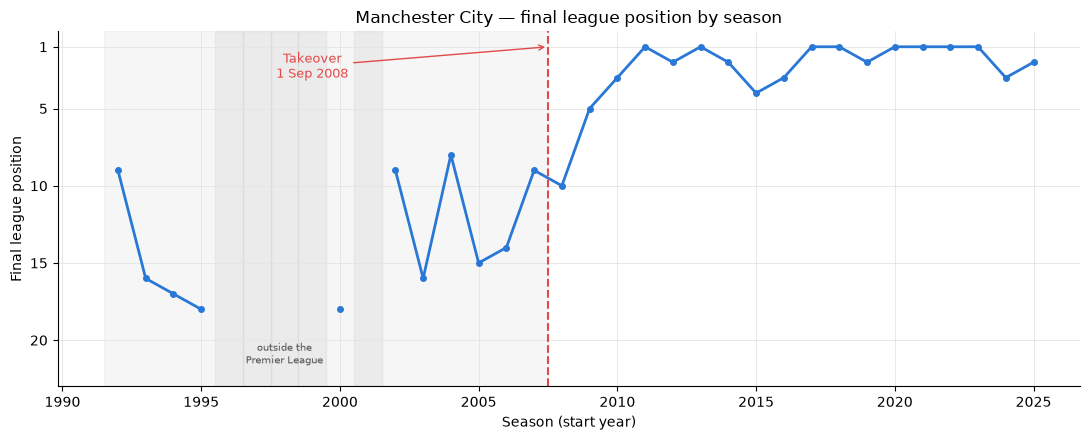

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))

full_years = pd.RangeIndex(all_seasons[0], all_seasons[-1] + 1, name="season_start_year")
series = city_positions.set_index("season_start_year")["position"].reindex(full_years)  # NaN = not in the PL

ax.plot(series.index, series.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.invert_yaxis()  # position 1 at the top
ax.set_ylim(23, 0)
ax.set_yticks([1, 5, 10, 15, 20])

ax.axvspan(all_seasons[0] - 0.5, TAKEOVER_SEASON_START_YEAR - 0.5, color=GRAY, alpha=0.08, zorder=0)
ax.axvline(TAKEOVER_SEASON_START_YEAR - 0.5, color=RED, linewidth=1.5, linestyle="--")
ax.annotate("Takeover\n1 Sep 2008", xy=(TAKEOVER_SEASON_START_YEAR - 0.5, 1),
            xytext=(1999, 3), color=RED, fontsize=9, ha="center",
            arrowprops=dict(arrowstyle="->", color=RED, lw=1))

for y in missing:
    ax.axvspan(y - 0.5, y + 0.5, color="#cccccc", alpha=0.25, zorder=0)
if missing:
    ax.text(missing[len(missing) // 2], 21.5, "outside the\nPremier League", ha="center", fontsize=7.5, color="#52514e")

ax.set_xlabel("Season (start year)")
ax.set_ylabel("Final league position")
ax.set_title("Manchester City — final league position by season")
fig.tight_layout()
plt.show()

The shift is stark: a mid-table (and occasionally relegation-threatened) club before 1 September 2008 became a top-4 fixture within two seasons of the takeover and has won the title in 8 of the 18 seasons from 2008-09 to 2025-26.

## 2. The table without Manchester City

`league_table()` already builds a season's standings from `team_matches`. If we first drop every row where Manchester City is either the team **or** the opponent, every remaining team's record only reflects matches against the other clubs — exactly "as if no team ever played Manchester City." We can reuse `league_table()` unchanged on that filtered data.

In [6]:
def league_table_excluding_team(team_matches: pd.DataFrame, season: str, excluded_team: str) -> pd.DataFrame:
    """A season's table as if `excluded_team` had never played — every other team keeps only
    its matches against the remaining clubs. For a standard 20-team season this gives a
    19-team table where each side has played 36 games instead of 38.
    """
    without = team_matches[
        (team_matches["team"] != excluded_team) & (team_matches["opponent"] != excluded_team)
    ]
    return league_table(without, season)


table_1112_actual = league_table(team_matches, "2011-12")
table_1112_without_city = league_table_excluding_team(team_matches, "2011-12", "Manchester City")
table_1112_without_city.head(5)

,team,played,wins,draws,losses,goals_for,goals_against,points,goal_diff
position,,,,,,,,,
1,Manchester United,36,28,5,3,88,26,89,62
2,Tottenham Hotspur,36,20,9,7,63,33,69,30
3,Arsenal,36,20,7,9,73,48,67,25
4,Newcastle United,36,19,8,9,55,46,65,9
5,Chelsea,36,17,10,9,62,43,61,19


In [7]:
# Tests: one fewer team, every remaining team played 2 games fewer (36 instead of 38),
# and every points/goal total dropped by what that team took off Manchester City
n_teams = len(table_1112_actual)
assert len(table_1112_without_city) == n_teams - 1
assert (table_1112_without_city["played"] == 38 - 2).all()

city_games = team_matches.query("season == '2011-12' and team == 'Manchester City'")
united = table_1112_actual.set_index("team").loc["Manchester United"]
united_wo = table_1112_without_city.set_index("team").loc["Manchester United"]
city_vs_united_points = city_games.query("opponent == 'Manchester United'")["points"].map({3: 0, 1: 1, 0: 3}).sum()  # points *United* took off City
assert united["points"] - united_wo["points"] == city_vs_united_points
print(f"Man Utd 2011-12: {united['points']} pts actual -> {united_wo['points']} pts without City "
      f"(took {city_vs_united_points} pts off them)")
print("league_table_excluding_team: OK")

Man Utd 2011-12: 89 pts actual -> 89 pts without City (took 0 pts off them)
league_table_excluding_team: OK


### Would anyone else have won the title?

Manchester City have won 8 Premier League titles since the takeover: 2011-12, 2013-14, 2017-18, 2018-19, 2020-21, 2021-22, 2022-23 and 2023-24. Run every one of those through `league_table_excluding_team` and check who tops the table in City's absence.

In [8]:
city_titles = city_positions.loc[city_positions["position"] == 1, "season"].tolist()

rows = []
for season in city_titles:
    actual = league_table(team_matches, season)
    without_city = league_table_excluding_team(team_matches, season, "Manchester City")
    runner_up = actual.iloc[1]
    hypothetical_champion = without_city.iloc[0]
    rows.append({
        "season": season,
        "actual_champion": "Manchester City",
        "actual_champion_pts": int(actual.iloc[0]["points"]),
        "runner_up": runner_up["team"],
        "runner_up_pts": int(runner_up["points"]),
        "champion_without_city": hypothetical_champion["team"],
        "pts_without_city": int(hypothetical_champion["points"]),
        "same_as_runner_up": hypothetical_champion["team"] == runner_up["team"],
    })

hypothetical = pd.DataFrame(rows)
hypothetical

,season,actual_champion,actual_champion_pts,runner_up,runner_up_pts,champion_without_city,pts_without_city,same_as_runner_up
0,2011-12,Manchester City,89,Manchester United,89,Manchester United,89,True
1,2013-14,Manchester City,86,Liverpool,84,Liverpool,81,True
2,2017-18,Manchester City,100,Manchester United,81,Manchester United,78,True
3,2018-19,Manchester City,98,Liverpool,97,Liverpool,96,True
4,2020-21,Manchester City,86,Manchester United,74,Manchester United,70,True
5,2021-22,Manchester City,93,Liverpool,92,Liverpool,90,True
6,2022-23,Manchester City,89,Arsenal,84,Arsenal,84,True
7,2023-24,Manchester City,91,Arsenal,89,Arsenal,85,True


In [9]:
# Test: the hypothetical champion is always the actual runner-up. Removing City only strips out
# each club's results against City, so the order below them can shift (see Section 3, 2020-21),
# but in none of these 8 seasons is the gap between 2nd and 3rd small enough for that to happen
assert hypothetical["same_as_runner_up"].all()
print(f"In all {len(hypothetical)} of City's title seasons, the runner-up would have won it without City.")
print(hypothetical["champion_without_city"].value_counts().rename("titles \'won\' without City").to_string())

In all 8 of City's title seasons, the runner-up would have won it without City.
champion_without_city
Manchester United    3
Liverpool            3
Arsenal              2


Removing Manchester City from a season doesn't change how the *other* clubs fared against each other — it only strips out their results against City. So the club immediately below City in the actual table is (in every one of these 8 seasons) still the best of the rest once City's results are taken out, and picks up the title in this hypothetical. Manchester United and Liverpool have the most to show for it: three "would-be" titles apiece.

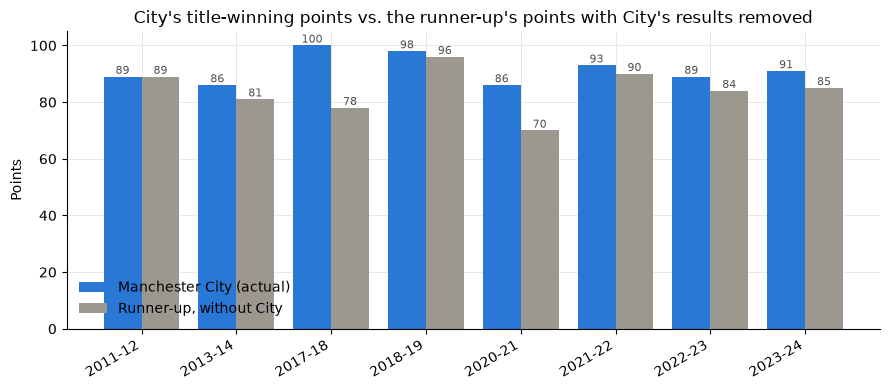

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(hypothetical))
ax.bar([i - 0.2 for i in x], hypothetical["actual_champion_pts"], width=0.4, color=BLUE, label="Manchester City (actual)")
ax.bar([i + 0.2 for i in x], hypothetical["pts_without_city"], width=0.4, color=GRAY, label="Runner-up, without City")
ax.set_xticks(list(x))
ax.set_xticklabels(hypothetical["season"], rotation=30, ha="right")
ax.set_ylabel("Points")
ax.set_title("City's title-winning points vs. the runner-up's points with City's results removed")
ax.legend(frameon=False)
for i, (a, b) in enumerate(zip(hypothetical["actual_champion_pts"], hypothetical["pts_without_city"])):
    ax.text(i - 0.2, a + 1, str(a), ha="center", fontsize=8, color="#52514e")
    ax.text(i + 0.2, b + 1, str(b), ha="center", fontsize=8, color="#52514e")
fig.tight_layout()
plt.show()

## 3. European qualification without Manchester City

City occupying a top-of-the-table spot doesn't just decide the title — it also takes a Champions League or Europa League place that would otherwise go to the next-best team. If City are removed from a season entirely, who picks up the European football they'd have missed out on the following season?

**Simplifying assumption, made explicit:** the modern-era rule of thumb is used — **top 4 → Champions League**, **5th → Europa League** — based on final league position alone. Real-world European qualification also depends on cup competitions not in this data (FA Cup and League Cup winners get their own Europa/Conference League berths, rolling down to the next-best league finisher if the cup winner already qualified via the table), and on one-off UEFA coefficient adjustments (e.g. an extra Champions League place for England from 2024-25). Those aren't modelled here — treat this as "what the table alone implies," not the confirmed European fields for these seasons.

Every post-takeover season in the data is now complete (2008-09 to 2025-26, 18 seasons). The `is_complete_season` check stays in as a guard, so a future partial download of a season in progress is left out rather than treated as a final table.

In [11]:
def is_complete_season(team_matches: pd.DataFrame, season: str) -> bool:
    """A season is complete if every team has played every other team home and away."""
    table = league_table(team_matches, season)
    return (table["played"] == (len(table) - 1) * 2).all()


def european_impact(team_matches: pd.DataFrame, season: str, excluded_team: str, cl_spots: int = 4) -> dict:
    """Compare the actual top-(cl_spots+1) with the table if `excluded_team` had never played.

    Returns the actual and hypothetical Champions League (top `cl_spots`) and Europa League
    (next place down) teams, and which teams gain a place when `excluded_team` is removed.
    """
    actual = league_table(team_matches, season)
    without = league_table_excluding_team(team_matches, season, excluded_team)

    actual_cl, actual_el = list(actual["team"].iloc[:cl_spots]), actual["team"].iloc[cl_spots]
    without_cl, without_el = list(without["team"].iloc[:cl_spots]), without["team"].iloc[cl_spots]

    return {
        "season": season,
        f"{excluded_team}_position": int(actual.index[actual["team"] == excluded_team][0]),
        "actual_cl": actual_cl, "actual_el": actual_el,
        "cl_without": without_cl, "el_without": without_el,
        "cl_gained": sorted(set(without_cl) - set(actual_cl)),
        "el_gained": without_el if without_el != actual_el else None,
    }


post_takeover_seasons = [s for s in city_positions["season"] if s >= TAKEOVER_SEASON]
complete_post_takeover = [s for s in post_takeover_seasons if is_complete_season(team_matches, s)]
print(f"{len(complete_post_takeover)} complete seasons since the takeover "
      f"(excluded as incomplete: {[s for s in post_takeover_seasons if s not in complete_post_takeover]})")

impact = pd.DataFrame([european_impact(team_matches, s, "Manchester City") for s in complete_post_takeover])
impact

18 complete seasons since the takeover (excluded as incomplete: [])


,season,Manchester City_position,actual_cl,actual_el,cl_without,el_without,cl_gained,el_gained
0,2008-09,10,"[Manchester United, Liverpool, Chelsea, Arsenal]",Everton,"[Manchester United, Liverpool, Chelsea, Arsenal]",Everton,[],NaN
1,2009-10,5,"[Chelsea, Manchester United, Arsenal, Tottenha...",Manchester City,"[Chelsea, Manchester United, Arsenal, Tottenha...",Aston Villa,[],Aston Villa
2,2010-11,3,"[Manchester United, Chelsea, Manchester City, ...",Tottenham Hotspur,"[Manchester United, Chelsea, Arsenal, Tottenha...",Liverpool,[Tottenham Hotspur],Liverpool
3,2011-12,1,"[Manchester City, Manchester United, Arsenal, ...",Newcastle United,"[Manchester United, Tottenham Hotspur, Arsenal...",Chelsea,[Newcastle United],Chelsea
4,2012-13,2,"[Manchester United, Manchester City, Chelsea, ...",Tottenham Hotspur,"[Manchester United, Chelsea, Arsenal, Tottenha...",Liverpool,[Tottenham Hotspur],Liverpool
5,2013-14,1,"[Manchester City, Liverpool, Chelsea, Arsenal]",Everton,"[Liverpool, Arsenal, Chelsea, Everton]",Tottenham Hotspur,[Everton],Tottenham Hotspur
6,2014-15,2,"[Chelsea, Manchester City, Arsenal, Manchester...",Tottenham Hotspur,"[Chelsea, Arsenal, Manchester United, Tottenha...",Southampton,[Tottenham Hotspur],Southampton
7,2015-16,4,"[Leicester City, Arsenal, Tottenham Hotspur, M...",Manchester United,"[Leicester City, Arsenal, Tottenham Hotspur, M...",Southampton,[Manchester United],Southampton
8,2016-17,3,"[Chelsea, Tottenham Hotspur, Manchester City, ...",Arsenal,"[Chelsea, Tottenham Hotspur, Arsenal, Liverpool]",Manchester United,[Arsenal],Manchester United
9,2017-18,1,"[Manchester City, Manchester United, Tottenham...",Chelsea,"[Manchester United, Tottenham Hotspur, Liverpo...",Arsenal,[Chelsea],Arsenal


In [12]:
# Test: City themselves never show up as a "gainer" (they're excluded from the without-City
# table by construction), and a team can only gain a spot in a season City actually occupied one
assert not impact["cl_gained"].apply(lambda teams: "Manchester City" in teams).any()
assert not (impact["el_gained"] == "Manchester City").any()
seasons_city_took_a_cl_or_el_spot = impact[impact["Manchester City_position"] <= 5]
has_change = seasons_city_took_a_cl_or_el_spot["cl_gained"].str.len().gt(0) | seasons_city_took_a_cl_or_el_spot["el_gained"].notna()
assert has_change.all(), "every season City finished top 5 should free exactly one CL or EL place"
print("european_impact: OK")

european_impact: OK


### Who benefits, and how often

In every season City finish 5th or better, removing them frees up exactly one Champions League **or** Europa League place (their own), which one extra club claims.

Usually that's the club directly below the European places. The one exception is 2020-21, below.

### The exception: 2020-21

Removing City doesn't take the same number of points off every club: each one loses exactly what it took from its two games against City. Usually that doesn't change the order below City, but in 2020-21 it does.

Leicester finished 5th on 66 points, one ahead of West Ham on 65. Leicester won 5-2 at City in September, so removing City's games costs them 3 points. West Ham only drew 1-1 with City (and lost the return game), so they lose 1. Without City, West Ham (64) finish above Leicester (63) and take the Champions League place, jumping from 6th to 4th. Leicester, the club directly below the top four, don't move up: they stay 5th, in the Europa League place they already had.

In [13]:
season = "2020-21"
actual = league_table(team_matches, season).reset_index()
without = league_table_excluding_team(team_matches, season, "Manchester City").reset_index()
vs_city = team_matches.query("season == @season and opponent == 'Manchester City'").groupby("team")["points"].sum()

clubs = ["Chelsea", "Leicester City", "West Ham United"]
exception = (
    actual.set_index("team").loc[clubs, ["position", "points"]].add_prefix("actual_")
    .join(vs_city.rename("points_taken_off_city"))
    .join(without.set_index("team").loc[clubs, ["position", "points", "goal_diff"]].add_prefix("without_city_"))
)
exception

,actual_position,actual_points,points_taken_off_city,without_city_position,without_city_points,without_city_goal_diff
team,,,,,,
Chelsea,4,67,3,3,64,23
Leicester City,5,66,3,5,63,17
West Ham United,6,65,1,4,64,16


In [14]:
# Test: West Ham overtake Leicester for the last Champions League place once City's results are removed
assert exception.loc["Leicester City", "actual_position"] == 5 and exception.loc["West Ham United", "actual_position"] == 6
assert exception.loc["West Ham United", "without_city_position"] == 4 and exception.loc["Leicester City", "without_city_position"] == 5
assert impact.set_index("season").loc[season, "cl_gained"] == ["West Ham United"]
print("2020-21: West Ham (6th) take the Champions League place, not Leicester (5th)")

2020-21: West Ham (6th) take the Champions League place, not Leicester (5th)


In [15]:
cl_gains = impact.explode("cl_gained").dropna(subset=["cl_gained"])
el_gains = impact.dropna(subset=["el_gained"])

print("Extra Champions League seasons gained, by team (with Manchester City removed):")
print(cl_gains["cl_gained"].value_counts().rename("seasons").to_string() or "  none")
print("\nExtra Europa League seasons gained, by team (with Manchester City removed):")
print(el_gains["el_gained"].value_counts().rename("seasons").to_string() or "  none")

print(f"\nSeasons City finished outside the European places (6th or lower) — no change: "
      f"{sorted(impact.loc[impact['Manchester City_position'] > 5, 'season'].tolist())}")

Extra Champions League seasons gained, by team (with Manchester City removed):
cl_gained
Tottenham Hotspur    4
Arsenal              3
Newcastle United     2
Liverpool            2
Everton              1
Manchester United    1
Chelsea              1
Leicester City       1
West Ham United      1

Extra Europa League seasons gained, by team (with Manchester City removed):
el_gained
Manchester United         3
Aston Villa               2
Liverpool                 2
Chelsea                   2
Southampton               2
Arsenal                   2
Tottenham Hotspur         1
Brighton & Hove Albion    1
Bournemouth               1

Seasons City finished outside the European places (6th or lower) — no change: ['2008-09']


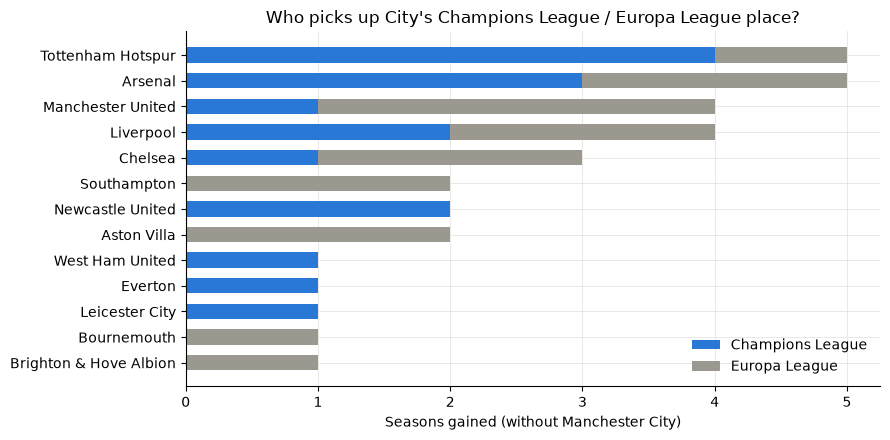

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
movers = pd.concat([
    cl_gains.assign(competition="Champions League", team=cl_gains["cl_gained"]),
    el_gains.assign(competition="Europa League", team=el_gains["el_gained"]),
])
counts = movers.groupby(["team", "competition"]).size().unstack(fill_value=0)
counts = counts.reindex(counts.sum(axis=1).sort_values(ascending=True).index)

left = pd.Series(0, index=counts.index)
for competition, color in [("Champions League", BLUE), ("Europa League", GRAY)]:
    if competition in counts:
        ax.barh(counts.index, counts[competition], left=left, color=color, label=competition, height=0.6)
        left += counts[competition]
ax.set_xlabel("Seasons gained (without Manchester City)")
ax.set_title("Who picks up City's Champions League / Europa League place?")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

## 4. Summary

- Manchester City's average final position went from **13.5** across the 11 top-flight seasons before the takeover to **2.4** across the 18 seasons from 2008-09 to 2025-26 — 0 titles before, 8 since, and a top-four finish every season from 2010-11 on.
- `league_table_excluding_team()` — new in this notebook — recomputes a season's table with one club's entire results removed. It's a thin wrapper around `league_table()`: filter `team_matches` to drop both sides of any fixture involving the excluded team, then run the existing aggregation.
- In every one of City's 8 post-takeover titles, the actual runner-up becomes champion once City's results are stripped out. Man United and Liverpool each "gain" 3 of those 8.
- Across all 18 post-takeover seasons, removing City frees a Champions League or Europa League place in each of the 17 they finished 5th or better. Usually the club directly below inherits it; the exception is 2020-21, when West Ham (6th) leapfrog Leicester (5th). See Section 3 for who picks those places up most often.

**Next step:** European qualification here only reflects league position, not cup competitions (FA Cup / League Cup winners get their own Europa/Conference League routes) — that would need cup results added to `raw_data/`, which the current sources don't include. `league_table_excluding_team()` is general — it works for any team, not just Manchester City. If more of this pattern shows up (e.g. excluding a team to study a different dynasty), move it into `scripts/data_utils.py` alongside `league_table`, following the same prototype-then-extract workflow as notebook 04.